<a href="https://colab.research.google.com/github/nikepb01/ComputerVision_Colab/blob/main/11%EA%B0%95_%EC%8B%A4%EC%8A%B5(%EC%9D%B4%EB%AF%B8%EC%A7%80_%EB%A7%A4%EC%B9%AD%EA%B3%BC_%EC%B6%94%EC%A0%81).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **실습8_이미지 매칭과 추적**

## 01 이미지 매칭

### 01.1 평균 해시 매칭(Average Hash Matching)

### 01.1-1 이미지 해시 처리 하기

In [ ]:
#구글 드라이브 마운트 하기
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


[[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0]
 [1 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0]
 [1 1 1 0 0 0 0 0 0 0 1 1 1 0 0 0]
 [0 1 1 0 0 1 1 0 1 0 0 1 0 0 1 0]
 [1 1 1 1 0 0 1 0 1 1 1 1 1 1 1 1]
 [1 1 1 1 0 0 0 0 0 1 0 1 1 1 1 1]
 [1 1 1 1 0 1 1 1 1 1 0 1 1 1 1 1]
 [1 1 1 1 1 0 1 0 1 0 1 1 1 1 1 1]
 [1 1 1 1 1 0 0 0 0 0 1 1 1 1 1 1]
 [1 1 1 1 1 0 0 0 0 0 0 1 0 1 1 1]
 [1 1 1 1 0 0 0 0 1 0 0 0 0 0 1 1]
 [1 1 1 1 1 0 0 0 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1]]

0000800800a018e0386692f2fff05ff7dffabff83ff817f083f8ffff7f


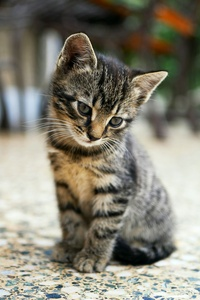

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

#img = cv2.imread("/content/drive/MyDrive/Colab Notebooks/photos/shapes/template/rabbitshape.jpg")
#img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/building300x200.jpg')
img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/11강/고양이_200x300.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 8x8 크기로 축소
gray = cv2.resize(gray, (16,16))
# 영상의 평균값 구하기
avg = gray.mean()
# 평균값을 기준으로 0과 1로 변환
bin = 1 * (gray > avg)
print(bin)
print("")

# 2진수 문자열을 16진수 문자열로 변환
dhash = []
for row in bin.tolist():
    s = ''.join([str(i) for i in row])
    dhash.append('%02x'%(int(s,2)))
dhash = ''.join(dhash)
print(dhash)

cv2_imshow(img)

### 01.1-2 해싱한 이미지 매칭하기

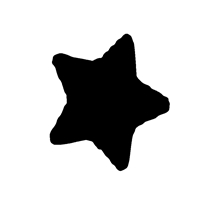

0.0


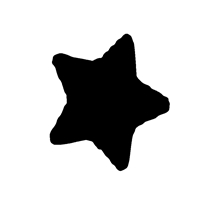

0.125


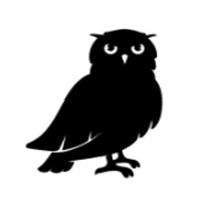

0.17578125


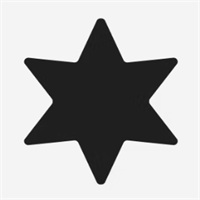

0.0


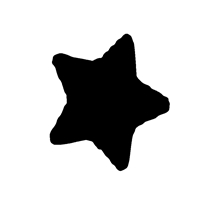

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
import glob


#img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/shapes/template/rabbitshape.jpg')
#search_dir = '/content/drive/MyDrive/Colab Notebooks/photos/shapes/'

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/11강/star_enhanced_200x200.jpg')
search_dir = '/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images'

cv2_imshow(img)

# 이미지를 16x16 크기의 평균 해쉬로 변환
def img2hash(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, (16, 16))
    avg = gray.mean()
    bi = 1 * (gray > avg)
    return bi

# 해밍거리 측정 함수
def hamming_distance(a, b):
    a = a.reshape(1,-1)
    b = b.reshape(1,-1)
    # 같은 자리의 값이 서로 다른 것들의 합
    distance = (a !=b).sum()
    return distance

# 기준 이미지 해쉬 구하기
query_hash = img2hash(img)

# 이미지 데이터 셋 디렉토리의 모든 영상 파일 경로
img_path = glob.glob(search_dir+'/**/*.jpg')

for path in img_path:
    img_comp = cv2.imread(path)
    # 데이터 셋 영상 한 개의 해시
    a_hash = img2hash(img_comp)
    # 해밍 거리 산출
    dst = hamming_distance(query_hash, a_hash)
    if dst/256 < 0.25: # 해밍거리 25% 이내만 출력
        print(dst/256)
        cv2_imshow(img_comp)

### 01.2 템플릿 매칭 (Template Matching)

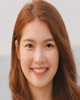

cv2.TM_CCOEFF_NORMED -0.4783664643764496 0.6358252763748169 (344, 291) (369, 168)


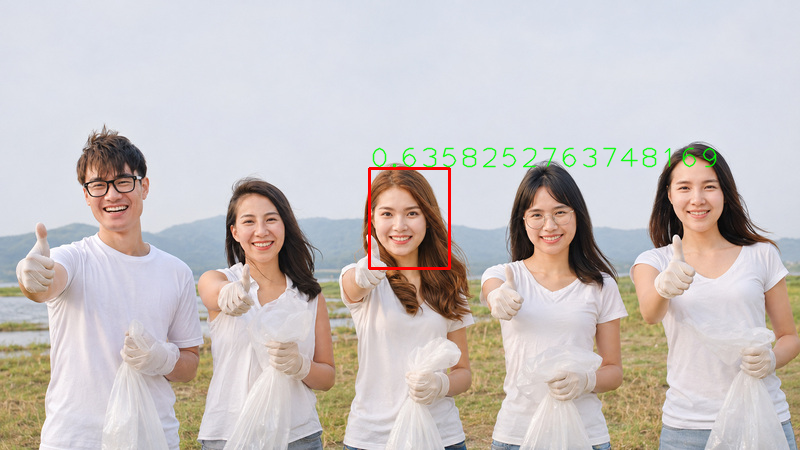

cv2.TM_CCORR_NORMED 0.724870502948761 0.9301332831382751 (656, 179) (369, 168)


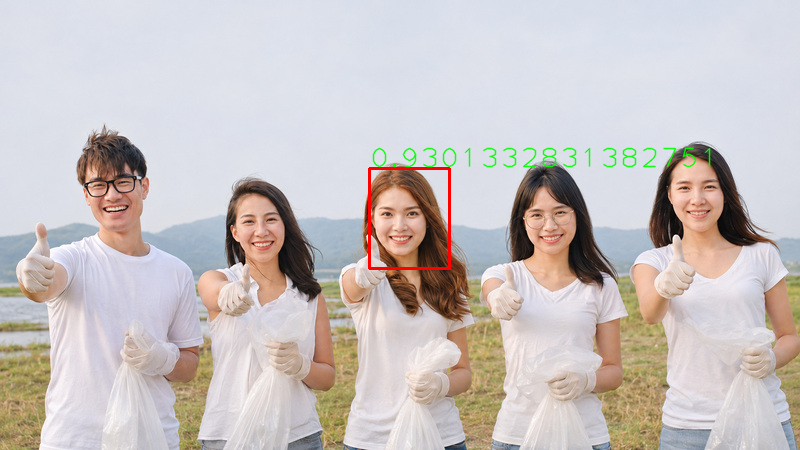

cv2.TM_SQDIFF_NORMED 0.13974934816360474 0.556014895439148 (369, 168) (656, 180)


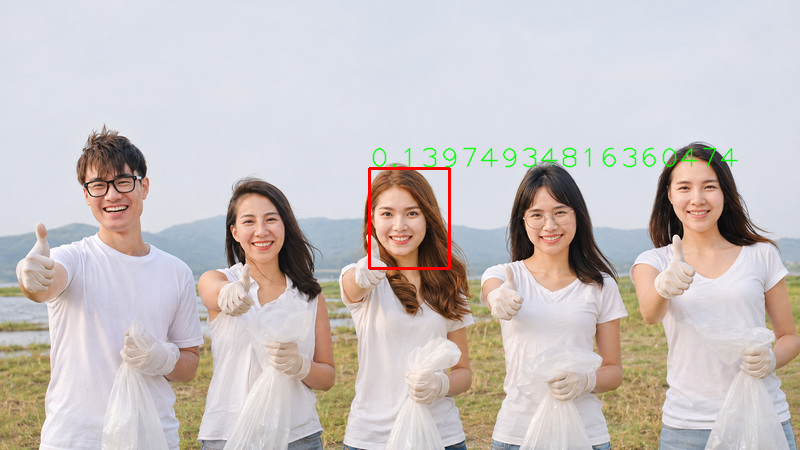

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# 입력이미지와 템플릿 이미지 읽기
#img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/shapes/shapes.jpg')
#template = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/shapes/template/starshape.jpg')

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/11강/group_photo_800x450.jpg')
template = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/11강/center_face_80x100.jpg')


th, tw = template.shape[:2]
cv2_imshow(template)

# 3가지 매칭 옵션
methods = ['cv2.TM_CCOEFF_NORMED', 'cv2.TM_CCORR_NORMED', 'cv2.TM_SQDIFF_NORMED']
for i, method_name in enumerate(methods):
    img_draw = img.copy()
    method = eval(method_name)
    # 템플릿 매칭
    res = cv2.matchTemplate(img, template, method)
    # 최대, 최소값과 그 좌표 구하기
    min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res)
    print(method_name, min_val, max_val, min_loc, max_loc)

    # TM_SQDIFF의 경우 최소값이 좋은 매칭, 나머지는 그 반대
    if method in [cv2.TM_SQDIFF, cv2.TM_SQDIFF_NORMED]:
        top_left = min_loc
        match_val = min_val
    else:
        top_left = max_loc
        match_val = max_val
    # 매칭 좌표 구해서 사각형 표시
    bottom_right = (top_left[0] + tw, top_left[1] + th)
    cv2.rectangle(img_draw, top_left, bottom_right, (0,0,255),2)
    # 매칭 포인트 표시
    cv2.putText(img_draw, str(match_val), top_left, \
                cv2.FONT_HERSHEY_PLAIN, 2,(0,255,0), 1, cv2.LINE_AA)
    cv2_imshow(img_draw)

### 01.3 복수 템플릿 매칭

In [ ]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


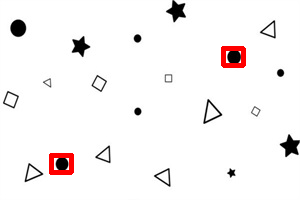

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/11강/shapes_300x200.jpg')
template = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/11강/one.jpg',cv2.IMREAD_GRAYSCALE)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

w, h = template.shape[::-1]
res = cv2.matchTemplate(gray,template,cv2.TM_CCOEFF_NORMED)
threshold = 0.83
loc = np.where( res >= threshold)
for pt in zip(*loc[::-1]):
    cv2.rectangle(img, pt, (pt[0] + w, pt[1] + h), (0,0,255), 2)

cv2_imshow(template)
cv2_imshow(img)

## **02 이미지의 특징**

### 02.1 해리스 코너 검출 (Harris Corner Detection)

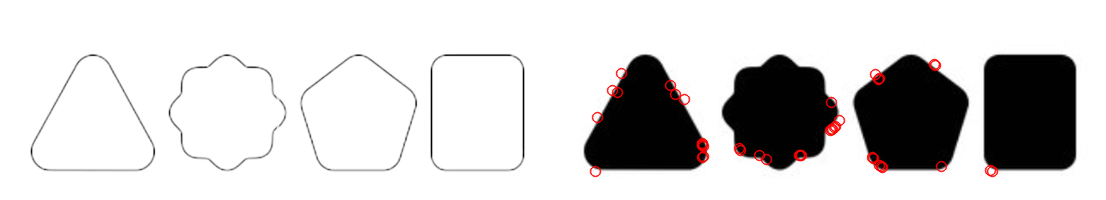

In [ ]:
import cv2
import numpy as np

#img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/11강/shapes_height200.jpg')
#img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/fish300x200.jpg')
img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/11강/shapes_height200.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 해리스 코너 검출
corner = cv2.cornerHarris(gray, 2, 3, 0.04)
# 변화량 결과의 최대값 10% 이상의 좌표 구하기
coord = np.where(corner > 0.1* corner.max())
coord = np.stack((coord[1], coord[0]), axis=-1)

# 코너 좌표에 동그리미 그리기
for x, y in coord:
    cv2.circle(img, (x,y), 5, (0,0,255), 1, cv2.LINE_AA)

# 변화량을 영상으로 표현하기 위해서 0~255로 정규화
corner_norm = cv2.normalize(corner, None, 0, 255, cv2.NORM_MINMAX, cv2.CV_8U)
# 화면에 출력
corner_norm = cv2.cvtColor(corner_norm, cv2.COLOR_GRAY2BGR)
merged = np.hstack((corner_norm, img))
cv2_imshow( merged)


### 02.2 시-토마시 검출 (Shi & Tomasi Detection)

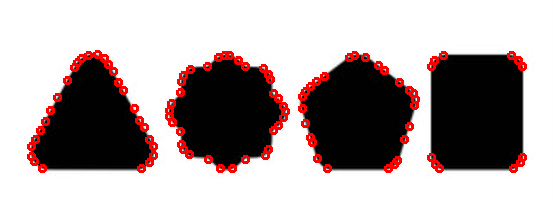

In [ ]:
import cv2
from google.colab.patches import cv2_imshow

#img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/building300x200.jpg')
#img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/fish300x200.jpg')
img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/11강/shapes_height200.jpg')

gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
corners = cv2.goodFeaturesToTrack(gray, 100, 0.01, 5, blockSize=3, useHarrisDetector=False, k=0.03)

for i in corners:
    # 실수를 정수형 좌표로 변환
    x, y = map(int, i[0])
    cv2.circle(img, (x, y), 3, (0, 0, 255), 2)

cv2_imshow(img)

### 02.3 FAST(Features from Accelerated Segment Test)

Threshold:  10
nonmaxSuppression:  True
neighborhood:  2
Total Keypoints with nonmaxSuppression:  139


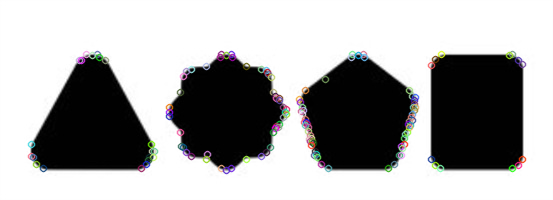

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

#img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/building300x200.jpg')
#img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/fish300x200.jpg')
img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/11강/shapes_height200.jpg')

fast = cv2.FastFeatureDetector_create()

fast.setThreshold(10)
#fast.setNonmaxSuppression(False)

kp = fast.detect(img,None)
result=cv2.drawKeypoints(img,kp,None)


print("Threshold: ", fast.getThreshold())
print("nonmaxSuppression: ", fast.getNonmaxSuppression())
print("neighborhood: ", fast.getType())
print("Total Keypoints with nonmaxSuppression: ", len(kp))

cv2_imshow(result)

# **03 얼굴 추적(Haar Cascades)**

### 03.1 얼굴 검출

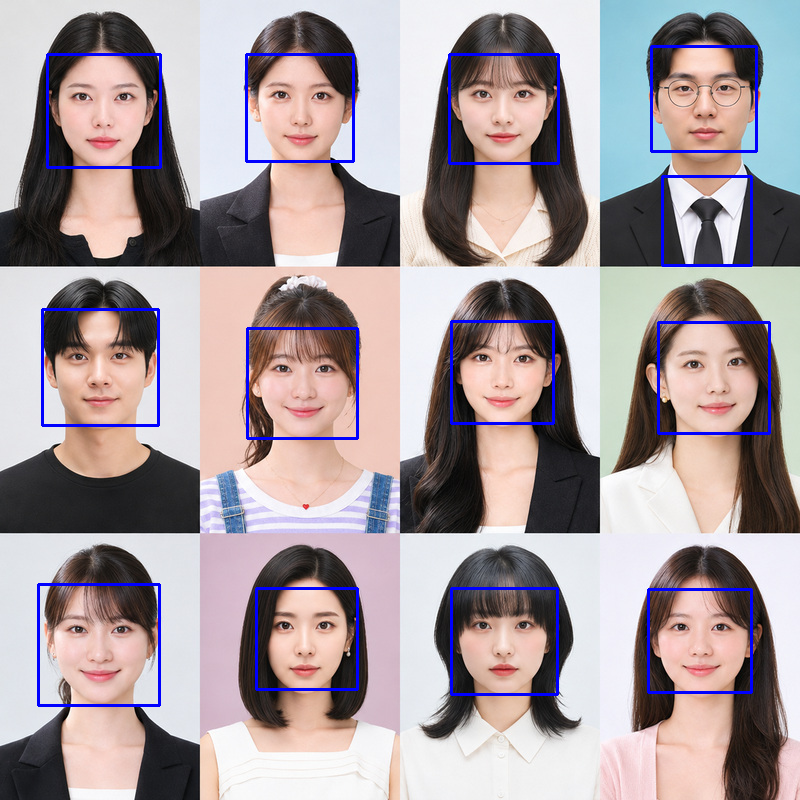

In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/11강/face_detection_800x800.jpg')
#img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/group_photo_800x450.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

face_cascade = cv2.CascadeClassifier(cv2.samples.findFile(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'))

faces = face_cascade.detectMultiScale(gray, 1.3, 3)
#faces = face_cascade.detectMultiScale(gray, 1.3, 2)

for (x,y,w,h) in faces:
     cv2.rectangle(img,(x,y),(x+w,y+h),(255,0,0),2)

cv2_imshow(img)

### 03.2 눈 검출

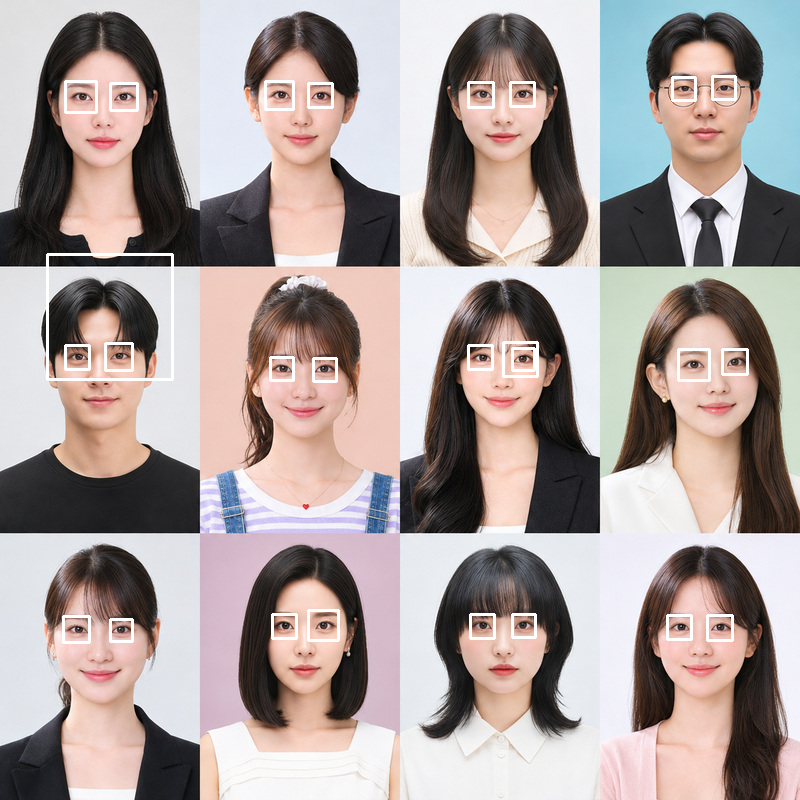

In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/11강/face_detection_800x800.jpg')
#img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/people_faces.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

eye_cascade = cv2.CascadeClassifier(cv2.samples.findFile(cv2.data.haarcascades + 'haarcascade_eye.xml'))
eyes = eye_cascade.detectMultiScale(gray, 1.3, 1)

for (x,y,w,h) in eyes:
  cv2.rectangle(img,(x,y),(x+w,y+h),(255,255,255),2)

cv2_imshow(img)

### 03.3 얼굴과 눈 검출

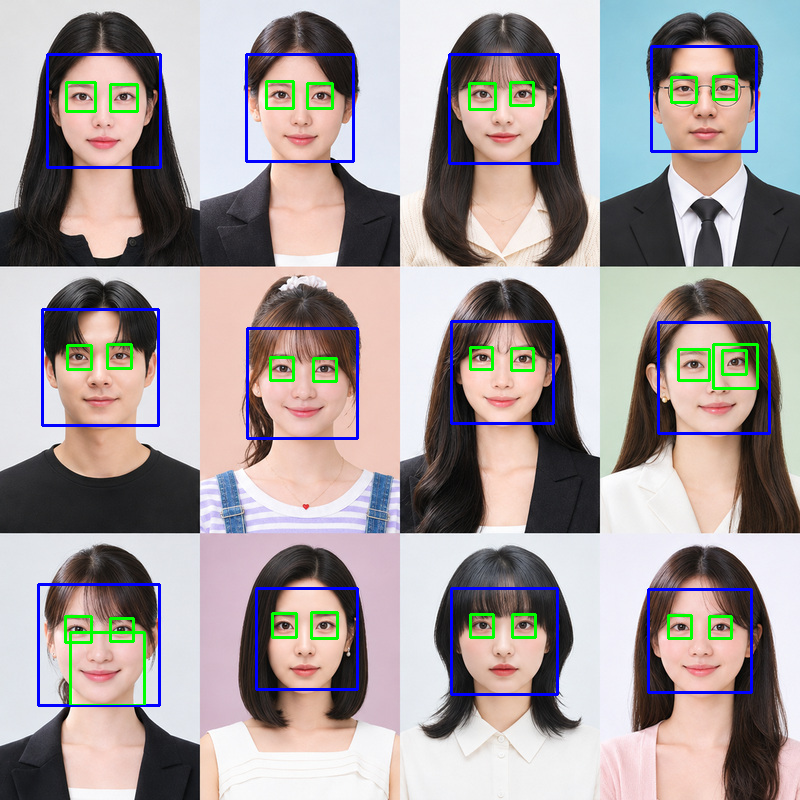

In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow

#img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/people.jpg')
img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/11강/face_detection_800x800.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

face_cascade = cv2.CascadeClassifier(cv2.samples.findFile(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'))
eye_cascade = cv2.CascadeClassifier(cv2.samples.findFile(cv2.data.haarcascades + 'haarcascade_eye.xml'))

faces = face_cascade.detectMultiScale(gray, 1.3, 4)
for (x,y,w,h) in faces:
    cv2.rectangle(img,(x,y),(x+w,y+h),(255,0,0),2)
    roi_gray = gray[y:y+h, x:x+w]
    roi_color = img[y:y+h, x:x+w]
    eyes = eye_cascade.detectMultiScale(roi_gray, 1.3, 1)
    for (ex,ey,ew,eh) in eyes:
        cv2.rectangle(roi_color,(ex,ey),(ex+ew,ey+eh),(0,255,0),2)

cv2_imshow(img)

### 03.4 웃는 입 검출

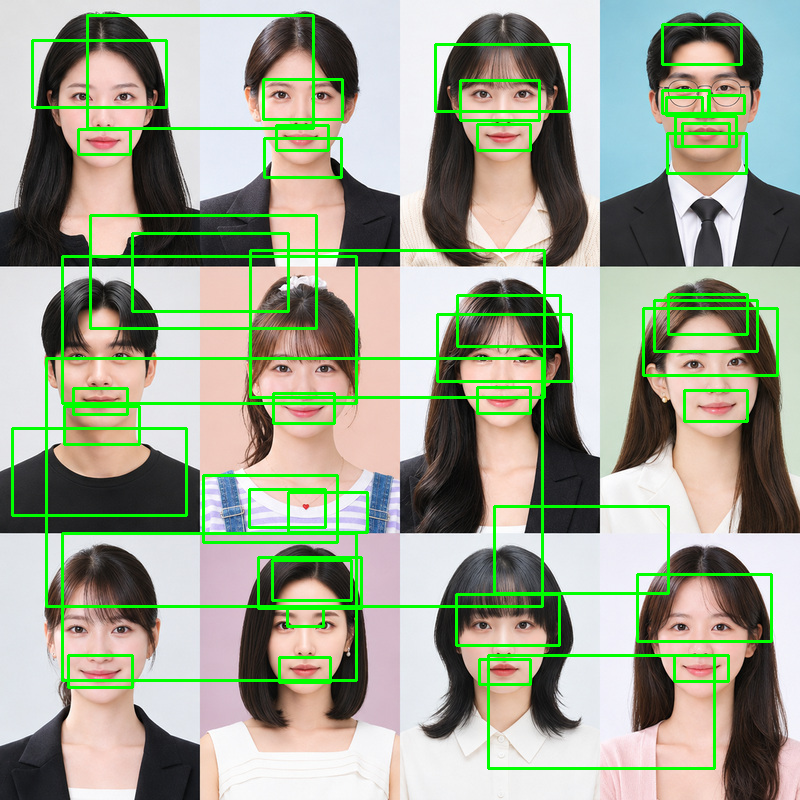

In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/11강/face_detection_800x800.jpg')
#img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/people_faces.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

smile_cascade = cv2.CascadeClassifier(cv2.samples.findFile(cv2.data.haarcascades +'haarcascade_smile.xml'))
smiles = smile_cascade.detectMultiScale(gray, 1.3, 2)
for (x,y,w,h) in smiles:
     cv2.rectangle(img,(x,y),(x+w,y+h),(0,255,0),2)

cv2_imshow(img)

### 03.5 얼굴과 웃는 입 검출

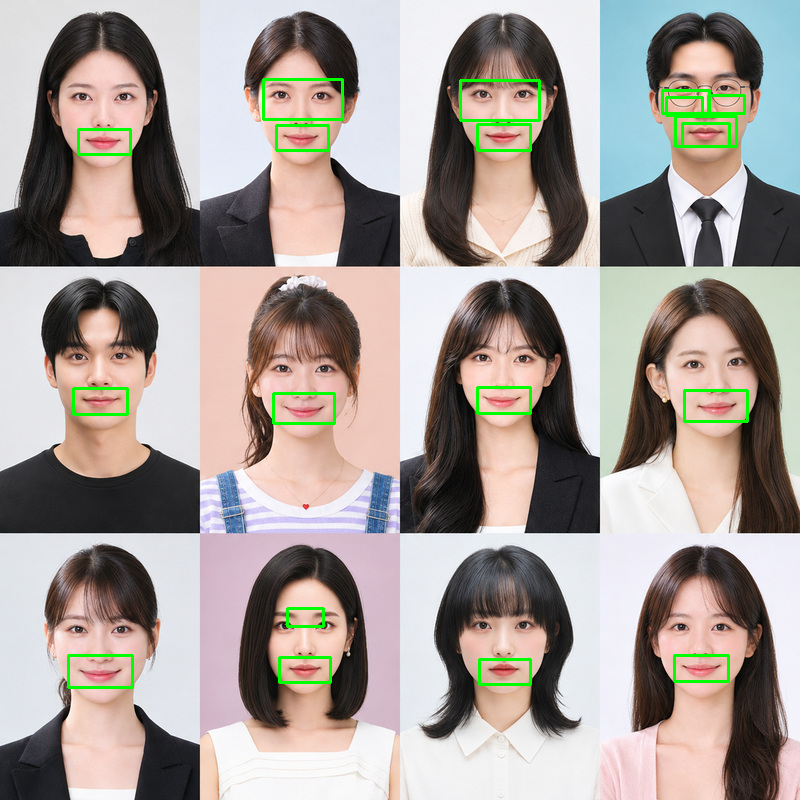

In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/11강/face_detection_800x800.jpg')
#img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/people_faces.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

face_cascade = cv2.CascadeClassifier(cv2.samples.findFile(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'))
smile_cascade = cv2.CascadeClassifier(cv2.samples.findFile(cv2.data.haarcascades +'haarcascade_smile.xml'))

faces = face_cascade.detectMultiScale(gray, 1.3, 1)
smiles = smile_cascade.detectMultiScale(gray, 1.3, 2)

for (x,y,w,h) in faces:
  for (x_s,y_s,w_s,h_s) in smiles:
    if( (x <= x_s) and (y <= y_s) and ( x+w >= x_s+w_s) and ( y+h >= y_s+h_s)):
      cv2.rectangle(img, (x_s,y_s),(x_s+w_s,y_s+h_s),(0,255,0),2)

cv2_imshow(img)

# 04 코랩에서 비디오 카메라 사용하기

## 04.1 코랩에서 제공하는 코드 불러오기

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename='myphoto.jpg', quality=0.9):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video element.
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for Capture to be clicked.
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

In [ ]:
from IPython.display import Image
try:
  filename = take_photo()
  print('Saved to {}'.format(filename))

  # Show the image which was just taken.
  display(Image(filename))
except Exception as err:
  # Errors will be thrown if the user does not have a webcam or if they do not
  # grant the page permission to access it.
  print(str(err))

In [ ]:
#필요한 라이브러리를 가져오기
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js
from base64 import b64decode, b64encode
import cv2
import numpy as np
import PIL
import io
import html
import time

In [ ]:
# 다른 확장자와 형식을 가진 이미지를 OpenCV 이미지 형식에 맞게 변환하는 함수
def js_to_image(js_reply):

  # base64 이미지로 디코드
  image_bytes = b64decode(js_reply.split(',')[1])
  # 넘파이 배열로 변환
  jpg_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
  # 넘파이 배열을 OpenCV BGR 이미지로 변환
  img = cv2.imdecode(jpg_as_np, flags=1)

  return img

In [ ]:
# Haar Cascade Classifier 파일 불러오기
face_cascade = cv2.CascadeClassifier(cv2.samples.findFile(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'))

In [ ]:
# 웹캠 연결하고 사진 찍는 함수 설정
def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video element.
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for Capture to be clicked.
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)

  # 사진 데이터 가져오기
  data = eval_js('takePhoto({})'.format(quality))
  # OpenCV 포멧으로 이미지 변환
  img = js_to_image(data)
  gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

  # Haar Cascade 함수를 사용해 얼굴 찾기
  faces = face_cascade.detectMultiScale(gray)
  for (x,y,w,h) in faces:
      img = cv2.rectangle(img,(x,y),(x+w,y+h),(255,0,0),2)

  #이미지 저장하기
  cv2.imwrite(filename, img)

  return filename

In [ ]:
# 웹캠 카메라 연결 후 사진찍기
try:
  filename = take_photo('photo.jpg')
  print('Saved to {}'.format(filename))

  # Show the image which was just taken.
  display(Image(filename))
except Exception as err:
  # Errors will be thrown if the user does not have a webcam or if they do not
  # grant the page permission to access it.
  print(str(err))

### 04.3 실시간 얼굴 추적

In [ ]:
# JavaScript to properly create our live video stream using our webcam as input
def video_stream():
  js = Javascript('''
    var video;
    var div = null;
    var stream;
    var captureCanvas;
    var imgElement;
    var labelElement;

    var pendingResolve = null;
    var shutdown = false;

    function removeDom() {
       stream.getVideoTracks()[0].stop();
       video.remove();
       div.remove();
       video = null;
       div = null;
       stream = null;
       imgElement = null;
       captureCanvas = null;
       labelElement = null;
    }

    function onAnimationFrame() {
      if (!shutdown) {
        window.requestAnimationFrame(onAnimationFrame);
      }
      if (pendingResolve) {
        var result = "";
        if (!shutdown) {
          captureCanvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
          result = captureCanvas.toDataURL('image/jpeg', 0.8)
        }
        var lp = pendingResolve;
        pendingResolve = null;
        lp(result);
      }
    }

    async function createDom() {
      if (div !== null) {
        return stream;
      }

      div = document.createElement('div');
      div.style.border = '2px solid black';
      div.style.padding = '3px';
      div.style.width = '100%';
      div.style.maxWidth = '600px';
      document.body.appendChild(div);

      const modelOut = document.createElement('div');
      modelOut.innerHTML = "<span>Status:</span>";
      labelElement = document.createElement('span');
      labelElement.innerText = 'No data';
      labelElement.style.fontWeight = 'bold';
      modelOut.appendChild(labelElement);
      div.appendChild(modelOut);

      video = document.createElement('video');
      video.style.display = 'block';
      video.width = div.clientWidth - 6;
      video.setAttribute('playsinline', '');
      video.onclick = () => { shutdown = true; };
      stream = await navigator.mediaDevices.getUserMedia(
          {video: { facingMode: "environment"}});
      div.appendChild(video);

      imgElement = document.createElement('img');
      imgElement.style.position = 'absolute';
      imgElement.style.zIndex = 1;
      imgElement.onclick = () => { shutdown = true; };
      div.appendChild(imgElement);

      const instruction = document.createElement('div');
      instruction.innerHTML =
          '<span style="color: red; font-weight: bold;">' +
          'When finished, click here or on the video to stop this demo</span>';
      div.appendChild(instruction);
      instruction.onclick = () => { shutdown = true; };

      video.srcObject = stream;
      await video.play();

      captureCanvas = document.createElement('canvas');
      captureCanvas.width = 640; //video.videoWidth;
      captureCanvas.height = 480; //video.videoHeight;
      window.requestAnimationFrame(onAnimationFrame);

      return stream;
    }
    async function stream_frame(label, imgData) {
      if (shutdown) {
        removeDom();
        shutdown = false;
        return '';
      }

      var preCreate = Date.now();
      stream = await createDom();

      var preShow = Date.now();
      if (label != "") {
        labelElement.innerHTML = label;
      }

      if (imgData != "") {
        var videoRect = video.getClientRects()[0];
        imgElement.style.top = videoRect.top + "px";
        imgElement.style.left = videoRect.left + "px";
        imgElement.style.width = videoRect.width + "px";
        imgElement.style.height = videoRect.height + "px";
        imgElement.src = imgData;
      }

      var preCapture = Date.now();
      var result = await new Promise(function(resolve, reject) {
        pendingResolve = resolve;
      });
      shutdown = false;

      return {'create': preShow - preCreate,
              'show': preCapture - preShow,
              'capture': Date.now() - preCapture,
              'img': result};
    }
    ''')

  display(js)

def bbox_to_bytes(bbox_array):
  # convert array into PIL image
  bbox_PIL = PIL.Image.fromarray(bbox_array, 'RGBA')
  iobuf = io.BytesIO()
  # format bbox into png for return
  bbox_PIL.save(iobuf, format='png')
  # format return string
  bbox_bytes = 'data:image/png;base64,{}'.format((str(b64encode(iobuf.getvalue()), 'utf-8')))

  return bbox_bytes

def video_frame(label, bbox):
  data = eval_js('stream_frame("{}", "{}")'.format(label, bbox))
  return data

In [ ]:
# start streaming video from webcam
video_stream()
# label for video
label_html = 'Capturing...'
# initialze bounding box to empty
bbox = ''
count = 0
while True:
    js_reply = video_frame(label_html, bbox)
    if not js_reply:
        break

    # convert JS response to OpenCV Image
    img = js_to_image(js_reply["img"])

    # create transparent overlay for bounding box
    bbox_array = np.zeros([480,640,4], dtype=np.uint8)

    # grayscale image for face detection
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    # get face region coordinates
    faces = face_cascade.detectMultiScale(gray)
    # get face bounding box for overlay
    for (x,y,w,h) in faces:
      bbox_array = cv2.rectangle(bbox_array,(x,y),(x+w,y+h),(255,0,0),2)

    bbox_array[:,:,3] = (bbox_array.max(axis = 2) > 0 ).astype(int) * 255
    # convert overlay of bbox into bytes
    bbox_bytes = bbox_to_bytes(bbox_array)
    # update bbox so next frame gets new overlay
    bbox = bbox_bytes

<IPython.core.display.Javascript object>

/tmp/ipykernel_448/2498818427.py:135: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  bbox_PIL = PIL.Image.fromarray(bbox_array, 'RGBA')
